# OBIS Exploratory Data Analysis

## Oceanographic AI Platform

### Objective
To investigate marine biodiversity patterns using OBIS
species occurrence records across the Arabian Sea and
Bay of Bengal.

### Study Period
2015–2025

### Study Regions
1. Arabian Sea
2. Bay of Bengal

### Analysis
- Dataset overview
- Data quality assessment
- Species distribution
- Temporal patterns
- Spatial distribution
- Regional comparison
- Sampling bias

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

In [13]:
df = pd.read_csv(
    "../data/processed/obis/obis_occurrences_clean.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1210, 124)


,basisOfRecord,brackish,catalogNumber,class,classid,collectionCode,coordinateUncertaintyInMeters,countryCode,datasetName,dateIdentified,...,scientificNameAuthorship,eventRemarks,gigaclass,gigaclassid,higherGeography,locationID,materialSampleID,superclass,superclassid,verbatimIdentification
0,HumanObservation,True,220859919.0,Elasmobranchii,10193,Observations,31418.0,MV,iNaturalist research-grade observations,2024-06-06T11:08:28Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,HumanObservation,True,338279950.0,Elasmobranchii,10193,Observations,31422.0,MV,iNaturalist research-grade observations,2026-02-12T03:44:33Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,HumanObservation,True,153189079.0,Elasmobranchii,10193,Observations,31407.0,MV,iNaturalist research-grade observations,2023-04-02T15:43:23Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HumanObservation,True,261391737.0,Elasmobranchii,10193,Observations,31418.0,MV,iNaturalist research-grade observations,2025-02-11T23:17:14Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,HumanObservation,True,327023714.0,Elasmobranchii,10193,Observations,31407.0,MV,iNaturalist research-grade observations,2025-11-17T22:23:57Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 1210
Number of columns: 124

Column Names:
['basisOfRecord', 'brackish', 'catalogNumber', 'class', 'classid', 'collectionCode', 'coordinateUncertaintyInMeters', 'countryCode', 'datasetName', 'dateIdentified', 'date_end', 'date_mid', 'date_start', 'date_year', 'decimalLatitude', 'decimalLongitude', 'eventDate', 'eventTime', 'family', 'familyid', 'genus', 'genusid', 'geodeticDatum', 'identificationID', 'identifiedBy', 'informationWithheld', 'infraclass', 'infraclassid', 'infraphylum', 'infraphylumid', 'institutionCode', 'kingdom', 'kingdomid', 'license', 'marine', 'modified', 'occurrenceID', 'occurrenceStatus', 'order', 'orderid', 'parvphylum', 'parvphylumid', 'phylum', 'phylumid', 'recordedBy', 'references', 'rightsHolder', 'scientificName', 'scientificNameID', 'species', 'speciesid', 'subclass', 'subclassid', 'subphylum', 'subphylumid', 'superdomain', 'superdomainid', 'superorder', 'superorderid', 'taxonID', 'taxonRank', 'verbatimEventDate', 'verbatimLocality', 'id', 'd

In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
basisOfRecord,1210,3,HumanObservation,732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brackish,1210,2,True,1071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
catalogNumber,705.0,NaN,NaN,NaN,219543239.951773,90897708.325534,2004845.0,152636387.0,236075905.0,281457333.0,379625526.0
class,1210,2,Elasmobranchii,734,NaN,NaN,NaN,NaN,NaN,NaN,NaN
classid,1210.0,NaN,NaN,NaN,121641.122314,138451.238228,10193.0,10193.0,10193.0,293496.0,293496.0
...,...,...,...,...,...,...,...,...,...,...,...
locationID,476,5,Sundarbans 5,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
materialSampleID,476,19,EE0362,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
superclass,476,1,Actinopteri,476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
superclassid,476.0,NaN,NaN,NaN,843664.0,0.0,843664.0,843664.0,843664.0,843664.0,843664.0


In [16]:
import os

print("Loaded file:")
print(os.path.abspath(
    "../data/processed/obis/obis_occurrences_clean.csv"
))

print("\nDataset shape:", df.shape)

Loaded file:
c:\Users\91911\oceanographic-ai-platform\data\processed\obis\obis_occurrences_clean.csv

Dataset shape: (1210, 124)


In [17]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing.head(30)

,Missing_Count,Missing_Percentage
waterBody,1208,99.834711
minimumDepthInMeters,1208,99.834711
eventID,1208,99.834711
scientificNameAuthorship,1208,99.834711
maximumDepthInMeters,1208,99.834711
depth,1208,99.834711
associatedSequences,1208,99.834711
footprintWKT,1207,99.752066
coordinatePrecision,1207,99.752066
continent,1187,98.099174


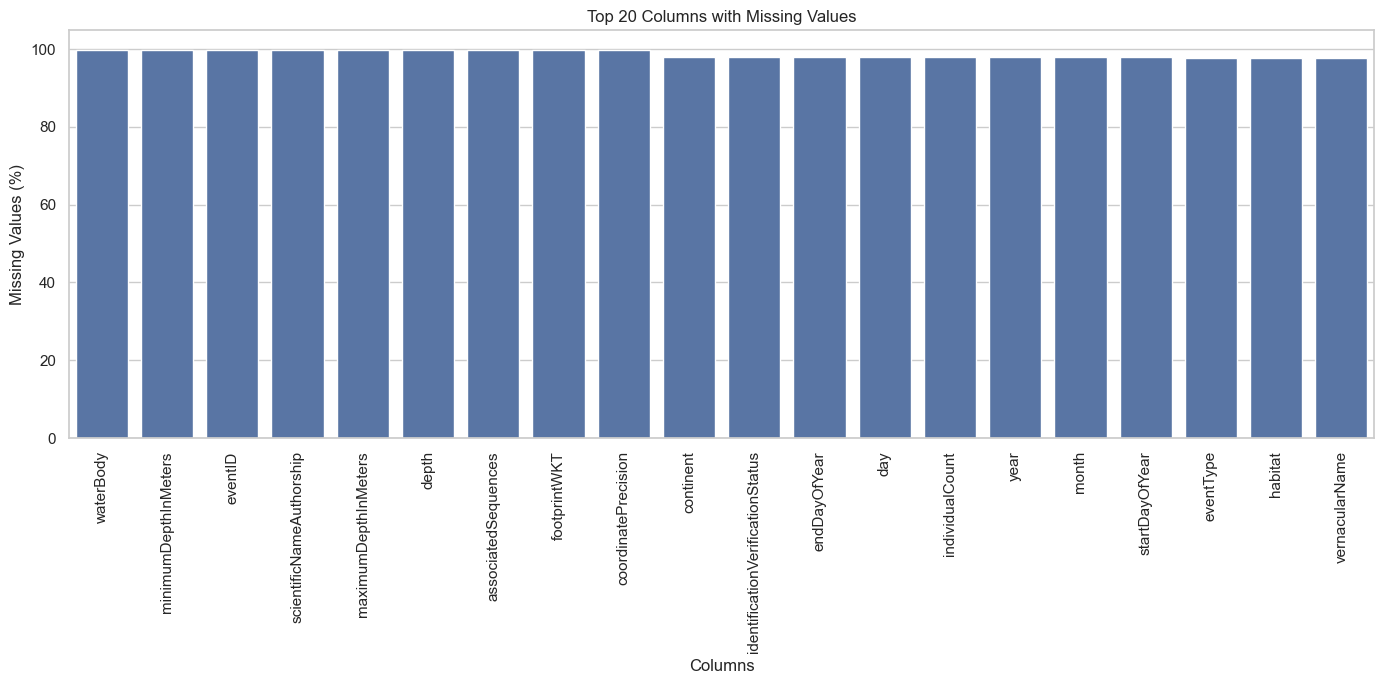

In [18]:
plt.figure(figsize=(14, 7))

sns.barplot(
    x=missing.head(20).index,
    y=missing.head(20)["Missing_Percentage"]
)

plt.xticks(rotation=90)
plt.ylabel("Missing Values (%)")
plt.xlabel("Columns")
plt.title("Top 20 Columns with Missing Values")

plt.tight_layout()
plt.show()

In [19]:
for i, col in enumerate(df.columns, 1):
    print(i, col)

1 basisOfRecord
2 brackish
3 catalogNumber
4 class
5 classid
6 collectionCode
7 coordinateUncertaintyInMeters
8 countryCode
9 datasetName
10 dateIdentified
11 date_end
12 date_mid
13 date_start
14 date_year
15 decimalLatitude
16 decimalLongitude
17 eventDate
18 eventTime
19 family
20 familyid
21 genus
22 genusid
23 geodeticDatum
24 identificationID
25 identifiedBy
26 informationWithheld
27 infraclass
28 infraclassid
29 infraphylum
30 infraphylumid
31 institutionCode
32 kingdom
33 kingdomid
34 license
35 marine
36 modified
37 occurrenceID
38 occurrenceStatus
39 order
40 orderid
41 parvphylum
42 parvphylumid
43 phylum
44 phylumid
45 recordedBy
46 references
47 rightsHolder
48 scientificName
49 scientificNameID
50 species
51 speciesid
52 subclass
53 subclassid
54 subphylum
55 subphylumid
56 superdomain
57 superdomainid
58 superorder
59 superorderid
60 taxonID
61 taxonRank
62 verbatimEventDate
63 verbatimLocality
64 id
65 dataset_id
66 node_id
67 dropped
68 absence
69 originalScientificNam

In [20]:
keywords = [
    "scientificName",
    "species",
    "eventDate",
    "decimalLatitude",
    "decimalLongitude",
    "year",
    "month",
    "class",
    "order",
    "family",
    "genus",
    "basisOfRecord",
    "locality",
    "locationID"
]

for keyword in keywords:
    matches = [
        col for col in df.columns
        if keyword.lower() in col.lower()
    ]

    print(f"{keyword}: {matches}")

scientificName: ['scientificName', 'scientificNameID', 'originalScientificName', 'scientificNameAuthorship']
species: ['species', 'speciesid']
eventDate: ['eventDate', 'verbatimEventDate']
decimalLatitude: ['decimalLatitude']
decimalLongitude: ['decimalLongitude']
year: ['date_year', 'endDayOfYear', 'startDayOfYear', 'year']
month: ['month']
class: ['class', 'classid', 'infraclass', 'infraclassid', 'subclass', 'subclassid', 'gigaclass', 'gigaclassid', 'superclass', 'superclassid']
order: ['order', 'orderid', 'superorder', 'superorderid']
family: ['family', 'familyid']
genus: ['genus', 'genusid']
basisOfRecord: ['basisOfRecord']
locality: ['verbatimLocality', 'locality']
locationID: ['locationID']


In [21]:
core_columns = [
    "scientificName",
    "species",
    "eventDate",
    "decimalLatitude",
    "decimalLongitude",
    "date_year",
    "month",
    "class",
    "order",
    "family",
    "genus",
    "basisOfRecord",
    "locality",
    "locationID"
]

core_columns = [
    col for col in core_columns
    if col in df.columns
]

core_quality = pd.DataFrame({
    "Non_Missing": df[core_columns].notna().sum(),
    "Missing": df[core_columns].isna().sum(),
    "Completeness_Percent":
        df[core_columns].notna().mean() * 100
})

core_quality.sort_values(
    "Completeness_Percent",
    ascending=False
)

,Non_Missing,Missing,Completeness_Percent
scientificName,1210,0,100.000000
species,1210,0,100.000000
eventDate,1210,0,100.000000
decimalLatitude,1210,0,100.000000
decimalLongitude,1210,0,100.000000
date_year,1210,0,100.000000
class,1210,0,100.000000
order,1210,0,100.000000
family,1210,0,100.000000
genus,1210,0,100.000000


In [22]:
print("Total records:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate species-date-coordinate combinations:",
    df.duplicated(
        subset=[
            "scientificName",
            "eventDate",
            "decimalLatitude",
            "decimalLongitude"
        ]
    ).sum()
)

Total records: 1210
Exact duplicate rows: 0
Duplicate species-date-coordinate combinations: 459


In [23]:
print("Latitude range:")
print(df["decimalLatitude"].describe())

print("\nLongitude range:")
print(df["decimalLongitude"].describe())

invalid_coordinates = df[
    (df["decimalLatitude"] < -90) |
    (df["decimalLatitude"] > 90) |
    (df["decimalLongitude"] < -180) |
    (df["decimalLongitude"] > 180)
]

print("\nInvalid coordinate records:", len(invalid_coordinates))

Latitude range:
count    1210.000000
mean       11.806471
std         8.388845
min         0.416549
25%         4.215778
50%         7.691812
75%        21.754890
max        24.575296
Name: decimalLatitude, dtype: float64

Longitude range:
count    1210.000000
mean       82.287907
std         9.723231
min        54.259465
25%        73.054321
50%        89.195000
75%        89.280875
max        99.991960
Name: decimalLongitude, dtype: float64

Invalid coordinate records: 0


In [24]:
df["eventDate_parsed"] = pd.to_datetime(
    df["eventDate"],
    errors="coerce",
    utc=True
)

print("Valid dates:", df["eventDate_parsed"].notna().sum())
print("Invalid dates:", df["eventDate_parsed"].isna().sum())

print("\nEarliest date:")
print(df["eventDate_parsed"].min())

print("\nLatest date:")
print(df["eventDate_parsed"].max())

Valid dates: 1210
Invalid dates: 0

Earliest date:
2015-01-01 04:57:12+00:00

Latest date:
2025-12-31 03:21:27+00:00


In [25]:
for col in df.columns:
    if any(word in col.lower() for word in [
        "region", "province", "country", "locality"
    ]):
        print(f"\n{col}")
        print(df[col].value_counts().head(10))


countryCode
countryCode
MV    508
TH    111
LK     26
MM      6
OM      5
IN      5
AE      3
XX      1
MY      1
Name: count, dtype: int64

verbatimLocality
verbatimLocality
Maldives                    321
Thailand                    107
Sri Lanka                    13
Tanintharyi, MM               3
Abu Dhabi, AE                 3
Oman                          2
India                         2
Muscat, OM                    1
Karnataka, IN                 1
South Andaman, IN-AN, IN      1
Name: count, dtype: int64

query_region
query_region
Bay of Bengal    634
Arabian Sea      576
Name: count, dtype: int64

country
country
Maldives     15
Sri Lanka     3
Thailand      3
Oman          2
India         2
world         1
Name: count, dtype: int64

locality
locality
Sundarban west wildlife sanctuary      186
Sundarbans west wildlife sanctuary     154
Sundarbans West Wildlife Sanctuary      63
Sundarban's west wildlife sanctuary     28
Sundarbans West Wildlife  Sanctuary     28
Sundarban 

In [26]:
def assign_region(row):

    lat = row["decimalLatitude"]
    lon = row["decimalLongitude"]

    if 50 <= lon < 78 and 0 <= lat <= 25:
        return "Arabian Sea"

    elif 78 <= lon <= 100 and 0 <= lat <= 23:
        return "Bay of Bengal"

    else:
        return "Outside Study Region"


df["region"] = df.apply(assign_region, axis=1)

print(df["region"].value_counts())

region
Bay of Bengal    634
Arabian Sea      576
Name: count, dtype: int64


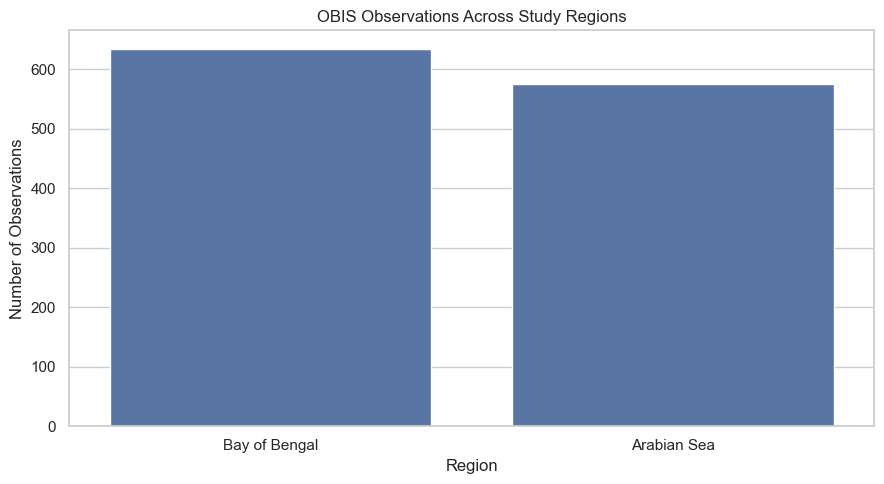

In [27]:
region_counts = df["region"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_counts.index,
    y=region_counts.values
)

plt.title("OBIS Observations Across Study Regions")
plt.xlabel("Region")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [28]:
df["year"] = df["eventDate_parsed"].dt.year
df["month"] = df["eventDate_parsed"].dt.month

print("Year range:")
print(df["year"].min(), "-", df["year"].max())

print("\nMonthly distribution:")
print(df["month"].value_counts().sort_index())

Year range:
2015 - 2025

Monthly distribution:
month
1     516
2      82
3     149
4      52
5      45
6      35
7      40
8      71
9      51
10     40
11     43
12     86
Name: count, dtype: int64


In [29]:
regional_summary = df.groupby("region").agg(
    total_records=("scientificName", "count"),
    unique_species=("scientificName", "nunique"),
    unique_families=("family", "nunique"),
    unique_orders=("order", "nunique"),
    first_observation=("eventDate_parsed", "min"),
    last_observation=("eventDate_parsed", "max")
)

regional_summary

,total_records,unique_species,unique_families,unique_orders,first_observation,last_observation
region,,,,,,
Arabian Sea,576,2,2,2,2015-01-15 00:01:00+00:00,2025-12-31 03:21:27+00:00
Bay of Bengal,634,3,3,3,2015-01-01 04:57:12+00:00,2025-12-30 03:17:00+00:00


In [30]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nLoaded dataset:")
print(os.path.abspath(
    "../data/processed/obis/obis_occurrences_clean.csv"
))

print("\nRows:", len(df))

Current working directory:
c:\Users\91911\oceanographic-ai-platform\notebooks

Loaded dataset:
c:\Users\91911\oceanographic-ai-platform\data\processed\obis\obis_occurrences_clean.csv

Rows: 1210


In [31]:
print("Unique scientific names:")
print(df["scientificName"].nunique())

print("\nSpecies list:")
print(
    df["scientificName"]
    .value_counts()
    .to_string()
)

Unique scientific names:
3

Species list:
scientificName
Carcharhinus melanopterus    595
Setipinna tenuifilis         476
Rhincodon typus              139


In [32]:
species_region = pd.crosstab(
    df["scientificName"],
    df["region"]
)

species_region

region,Arabian Sea,Bay of Bengal
scientificName,,
Carcharhinus melanopterus,469,126
Rhincodon typus,107,32
Setipinna tenuifilis,0,476


In [33]:
for col in ["class", "order", "family", "genus"]:

    print(f"\nUnique {col}:")
    print(df[col].nunique())

    print(df[col].value_counts())


Unique class:
2
class
Elasmobranchii    734
Teleostei         476
Name: count, dtype: int64

Unique order:
3
order
Carcharhiniformes    595
Clupeiformes         476
Orectolobiformes     139
Name: count, dtype: int64

Unique family:
3
family
Carcharhinidae    595
Engraulidae       476
Rhincodontidae    139
Name: count, dtype: int64

Unique genus:
3
genus
Carcharhinus    595
Setipinna       476
Rhincodon       139
Name: count, dtype: int64


In [34]:
yearly = df.groupby(
    ["year", "region"]
).size().unstack(fill_value=0)

yearly

region,Arabian Sea,Bay of Bengal
year,,
2015,18,8
2016,5,1
2017,10,5
2018,12,10
2019,36,9
2020,15,18
2021,30,2
2022,59,19
2023,85,497


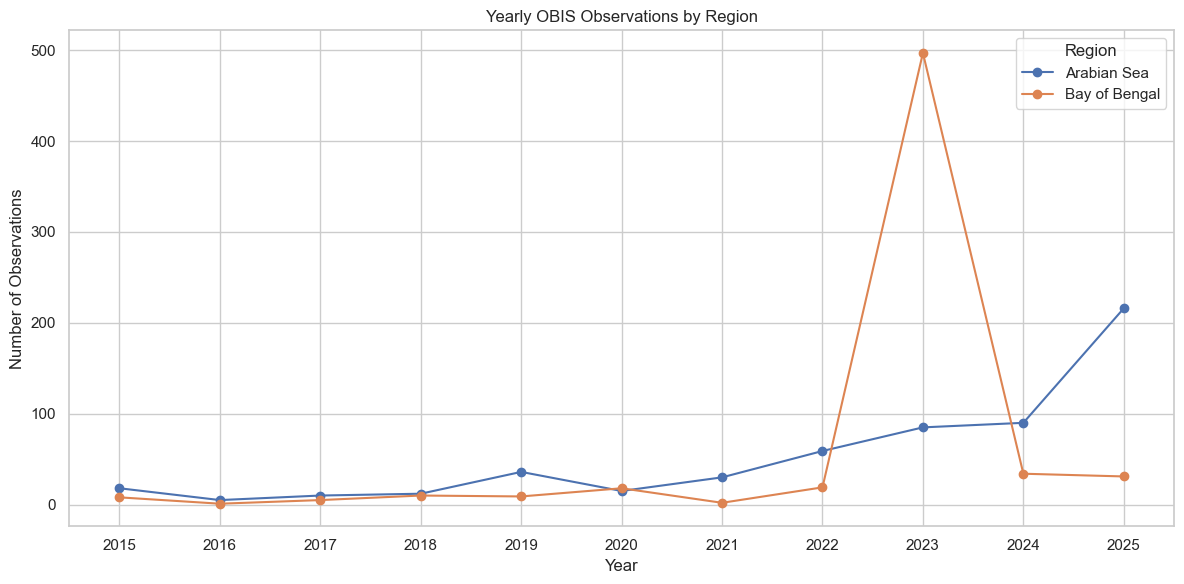

In [35]:
yearly.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Yearly OBIS Observations by Region")
plt.xlabel("Year")
plt.ylabel("Number of Observations")
plt.xticks(range(2015, 2026))
plt.legend(title="Region")
plt.grid(True)

plt.tight_layout()
plt.show()

In [36]:
# Investigate 2023 observations

spike_2023 = df[df["year"] == 2023]

print("2023 total observations:", len(spike_2023))

print("\nSpecies distribution in 2023:")
print(spike_2023["scientificName"].value_counts())

print("\nRegional distribution in 2023:")
print(spike_2023["region"].value_counts())

print("\nSpecies by region in 2023:")
print(
    pd.crosstab(
        spike_2023["scientificName"],
        spike_2023["region"]
    )
)

2023 total observations: 582

Species distribution in 2023:
scientificName
Setipinna tenuifilis         476
Carcharhinus melanopterus     91
Rhincodon typus               15
Name: count, dtype: int64

Regional distribution in 2023:
region
Bay of Bengal    497
Arabian Sea       85
Name: count, dtype: int64

Species by region in 2023:
region                     Arabian Sea  Bay of Bengal
scientificName                                       
Carcharhinus melanopterus           73             18
Rhincodon typus                     12              3
Setipinna tenuifilis                 0            476


In [37]:
for col in ["datasetName", "institutionCode",
            "collectionCode", "basisOfRecord"]:

    if col in spike_2023.columns:
        print(f"\n{col}:")
        print(spike_2023[col].value_counts().head(15))


datasetName:
datasetName
iNaturalist research-grade observations    101
Name: count, dtype: int64

institutionCode:
institutionCode
iNaturalist    101
Name: count, dtype: int64

collectionCode:
collectionCode
Observations    101
Name: count, dtype: int64

basisOfRecord:
basisOfRecord
MachineObservation    476
HumanObservation      106
Name: count, dtype: int64


In [38]:
# Investigate the 2023 Setipinna observations

spike_species = spike_2023[
    spike_2023["scientificName"] == "Setipinna tenuifilis"
]

print("Total Setipinna observations:", len(spike_species))

print("\nObservation dates:")
print(spike_species["eventDate"].value_counts().head(15))

print("\nMonthly distribution:")
print(spike_species["month"].value_counts().sort_index())

print("\nMetadata distribution:")

for col in [
    "datasetName",
    "institutionCode",
    "collectionCode",
    "basisOfRecord",
    "recordedBy"
]:
    if col in spike_species.columns:
        print(f"\n{col}:")
        print(spike_species[col].value_counts().head(15))

Total Setipinna observations: 476

Observation dates:
eventDate
2023-01-09 00:00:00+00:00    321
2023-01-08 00:00:00+00:00    155
Name: count, dtype: int64

Monthly distribution:
month
1    476
Name: count, dtype: int64

Metadata distribution:

datasetName:
Series([], Name: count, dtype: int64)

institutionCode:
Series([], Name: count, dtype: int64)

collectionCode:
Series([], Name: count, dtype: int64)

basisOfRecord:
basisOfRecord
MachineObservation    476
Name: count, dtype: int64

recordedBy:
recordedBy
Hugo Gante    476
Name: count, dtype: int64


In [39]:
print("Unique coordinates:")
print(
    spike_species[
        ["decimalLatitude", "decimalLongitude"]
    ].drop_duplicates().shape[0]
)

print("\nUnique observation dates:")
print(spike_species["eventDate"].nunique())

Unique coordinates:
17

Unique observation dates:
2


In [40]:
# Examine observations by date and coordinates

print("Observations per date and coordinate:")

date_location = (
    spike_species
    .groupby([
        "eventDate",
        "decimalLatitude",
        "decimalLongitude"
    ])
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

print(date_location.to_string(index=False))

Observations per date and coordinate:
                eventDate  decimalLatitude  decimalLongitude  record_count
2023-01-08 00:00:00+00:00        21.827841         89.195423            65
2023-01-08 00:00:00+00:00        21.756580         89.223058            38
2023-01-08 00:00:00+00:00        21.756580         89.223017            36
2023-01-09 00:00:00+00:00        21.703931         89.261001            36
2023-01-09 00:00:00+00:00        21.703917         89.260995            35
2023-01-09 00:00:00+00:00        21.703521         89.261482            29
2023-01-09 00:00:00+00:00        21.754752         89.283835            29
2023-01-09 00:00:00+00:00        21.754890         89.284180            28
2023-01-09 00:00:00+00:00        21.754946         89.283766            28
2023-01-09 00:00:00+00:00        21.793305         89.280875            28
2023-01-09 00:00:00+00:00        21.793313         89.281088            26
2023-01-09 00:00:00+00:00        21.703926         89.261013  

In [41]:
# Coordinate-level distribution

coordinate_counts = (
    spike_species
    .groupby([
        "decimalLatitude",
        "decimalLongitude"
    ])
    .size()
    .reset_index(name="observations")
    .sort_values("observations", ascending=False)
)

print(coordinate_counts.to_string(index=False))

print("\nCoordinate statistics:")
print(coordinate_counts["observations"].describe())

 decimalLatitude  decimalLongitude  observations
       21.827841         89.195423            65
       21.756580         89.223058            38
       21.703931         89.261001            36
       21.756580         89.223017            36
       21.703917         89.260995            35
       21.703521         89.261482            29
       21.754752         89.283835            29
       21.754890         89.284180            28
       21.754946         89.283766            28
       21.793305         89.280875            28
       21.703926         89.261013            26
       21.793313         89.281088            26
       21.754740         89.283996            22
       21.756639         89.222982            17
       21.793210         89.281313            17
       21.828443         89.195000             9
       21.756641         89.223120             7

Coordinate statistics:
count    17.000000
mean     28.000000
std      13.076697
min       7.000000
25%      22.000000

In [42]:
metadata_columns = [
    "datasetName",
    "institutionCode",
    "collectionCode",
    "basisOfRecord",
    "recordedBy",
    "occurrenceID",
    "eventID",
    "catalogNumber"
]

for col in metadata_columns:

    if col in spike_species.columns:

        print(f"\n{col}")

        print(
            "Missing:",
            spike_species[col].isna().sum()
        )

        print(
            "Unique:",
            spike_species[col].nunique()
        )

        print(
            spike_species[col].dropna().value_counts().head(10)
        )


datasetName
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

institutionCode
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

collectionCode
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

basisOfRecord
Missing: 0
Unique: 1
basisOfRecord
MachineObservation    476
Name: count, dtype: int64

recordedBy
Missing: 0
Unique: 1
recordedBy
Hugo Gante    476
Name: count, dtype: int64

occurrenceID
Missing: 0
Unique: 476
occurrenceID
asv.1721_EE0362_12s_mifish      1
asv.322_EE0332_12s_mifish       1
asv.6_EE0334_12s_teleo          1
asv.37_EE0337_12s_mifish        1
asv.508_EE0334_12s_mimammal     1
asv.42_EE0360_12s_mimammal      1
asv.164_EE0362_12s_teleo        1
asv.1875_EE0362_12s_mimammal    1
asv.855_EE0350_12s_mimammal     1
asv.1721_EE0348_12s_mifish      1
Name: count, dtype: int64

eventID
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

catalogNumber
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)


In [43]:
# Investigate record identifiers

identifier_columns = [
    "occurrenceID",
    "eventID",
    "id",
    "gbifID",
    "references",
    "identificationReferences",
    "datasetID",
    "institutionID"
]

for col in identifier_columns:

    if col in spike_species.columns:

        print(f"\n========== {col} ==========")

        print("Missing:",
              spike_species[col].isna().sum())

        print("Unique:",
              spike_species[col].nunique())

        print("Sample values:")

        print(
            spike_species[col]
            .dropna()
            .head(10)
            .to_string(index=False)
        )


========== occurrenceID ==========
Missing: 0
Unique: 476
Sample values:
   asv.322_EE0332_12s_mifish
      asv.6_EE0334_12s_teleo
    asv.37_EE0337_12s_mifish
 asv.508_EE0334_12s_mimammal
  asv.42_EE0360_12s_mimammal
    asv.164_EE0362_12s_teleo
asv.1875_EE0362_12s_mimammal
 asv.855_EE0350_12s_mimammal
  asv.1721_EE0348_12s_mifish
    asv.179_EE0347_12s_teleo

========== eventID ==========
Missing: 476
Unique: 0
Sample values:
Series([], )

========== id ==========
Missing: 0
Unique: 476
Sample values:
002e1204-4c5e-44e5-8ebe-e9598940eb8a
005c90be-9719-461b-a615-964d44bb57ab
0090bc51-7b63-4ea0-b98d-2665300cf284
011aef6b-aa92-4371-9576-501fa7a94c8d
0188607b-d39f-49f6-a369-ecc5b874bda1
01f3c62c-211a-4734-9f48-3becb9dc5432
02f11a81-c380-4eca-b03f-a4f21f776a3c
035843a7-c038-4024-9d12-afb42c6decf4
03964480-60b1-477c-9d4e-daf068394ed1
039a11f3-5487-456f-a49c-014512561ce7

========== references ==========
Missing: 476
Unique: 0
Sample values:
Series([], )


In [44]:
# Display selected original records

inspect_columns = [
    "scientificName",
    "eventDate",
    "decimalLatitude",
    "decimalLongitude",
    "recordedBy",
    "basisOfRecord",
    "occurrenceID",
    "eventID",
    "references"
]

available_columns = [
    col for col in inspect_columns
    if col in spike_species.columns
]

display(
    spike_species[available_columns].head(15)
)

,scientificName,eventDate,decimalLatitude,decimalLongitude,recordedBy,basisOfRecord,occurrenceID,eventID,references
734,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.793210,89.281313,Hugo Gante,MachineObservation,asv.322_EE0332_12s_mifish,NaN,NaN
735,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.703926,89.261013,Hugo Gante,MachineObservation,asv.6_EE0334_12s_teleo,NaN,NaN
736,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.754752,89.283835,Hugo Gante,MachineObservation,asv.37_EE0337_12s_mifish,NaN,NaN
737,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.703926,89.261013,Hugo Gante,MachineObservation,asv.508_EE0334_12s_mimammal,NaN,NaN
738,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.793313,89.281088,Hugo Gante,MachineObservation,asv.42_EE0360_12s_mimammal,NaN,NaN
739,Setipinna tenuifilis,2023-01-08 00:00:00+00:00,21.756580,89.223058,Hugo Gante,MachineObservation,asv.164_EE0362_12s_teleo,NaN,NaN
740,Setipinna tenuifilis,2023-01-08 00:00:00+00:00,21.756580,89.223058,Hugo Gante,MachineObservation,asv.1875_EE0362_12s_mimammal,NaN,NaN
741,Setipinna tenuifilis,2023-01-09 00:00:00+00:00,21.703917,89.260995,Hugo Gante,MachineObservation,asv.855_EE0350_12s_mimammal,NaN,NaN
742,Setipinna tenuifilis,2023-01-08 00:00:00+00:00,21.756580,89.223017,Hugo Gante,MachineObservation,asv.1721_EE0348_12s_mifish,NaN,NaN
743,Setipinna tenuifilis,2023-01-08 00:00:00+00:00,21.827841,89.195423,Hugo Gante,MachineObservation,asv.179_EE0347_12s_teleo,NaN,NaN


In [45]:
# Investigate Setipinna observation metadata

spike = df[
    df["scientificName"] == "Setipinna tenuifilis"
].copy()

print("Total observations:", len(spike))

# Check available metadata columns
metadata_cols = [
    col for col in spike.columns
    if any(keyword in col.lower() for keyword in [
        "dataset",
        "institution",
        "collection",
        "reference",
        "event",
        "sampling",
        "recorded",
        "basis",
        "associated",
        "sequence",
        "remarks",
        "identified"
    ])
]

print("\nMetadata columns:")
print(metadata_cols)

print("\nMetadata summary:")

for col in metadata_cols:
    print(f"\n{col}:")
    print("Missing:", spike[col].isna().sum())
    print("Unique:", spike[col].nunique())
    print(spike[col].value_counts().head(10))

Total observations: 476

Metadata columns:
['basisOfRecord', 'collectionCode', 'datasetName', 'dateIdentified', 'eventDate', 'eventTime', 'identifiedBy', 'institutionCode', 'recordedBy', 'references', 'verbatimEventDate', 'dataset_id', 'identifiedByID', 'recordedByID', 'occurrenceRemarks', 'eventType', 'samplingProtocol', 'identificationRemarks', 'associatedSequences', 'eventID', 'eventRemarks', 'eventDate_parsed']

Metadata summary:

basisOfRecord:
Missing: 0
Unique: 1
basisOfRecord
MachineObservation    476
Name: count, dtype: int64

collectionCode:
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

datasetName:
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

dateIdentified:
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

eventDate:
Missing: 0
Unique: 2
eventDate
2023-01-09 00:00:00+00:00    321
2023-01-08 00:00:00+00:00    155
Name: count, dtype: int64

eventTime:
Missing: 476
Unique: 0
Series([], Name: count, dtype: int64)

identifiedBy:
Missi

In [46]:
print("Occurrence ID patterns:")

print(
    spike["occurrenceID"]
    .str.extract(r"_(12s_[^_]+)$")[0]
    .value_counts()
)

print("\nObservation distribution by date and region:")

print(
    spike.groupby(
        ["eventDate", "region"]
    ).size()
)

Occurrence ID patterns:
0
12s_teleo       194
12s_mifish      126
12s_mimammal    118
Name: count, dtype: int64

Observation distribution by date and region:
eventDate                  region       
2023-01-08 00:00:00+00:00  Bay of Bengal    155
2023-01-09 00:00:00+00:00  Bay of Bengal    321
dtype: int64


In [47]:
# Inspect all available columns

print("Total columns:", len(spike.columns))

print("\nAll available columns:")

for col in spike.columns:
    print(col)

Total columns: 126

All available columns:
basisOfRecord
brackish
catalogNumber
class
classid
collectionCode
coordinateUncertaintyInMeters
countryCode
datasetName
dateIdentified
date_end
date_mid
date_start
date_year
decimalLatitude
decimalLongitude
eventDate
eventTime
family
familyid
genus
genusid
geodeticDatum
identificationID
identifiedBy
informationWithheld
infraclass
infraclassid
infraphylum
infraphylumid
institutionCode
kingdom
kingdomid
license
marine
modified
occurrenceID
occurrenceStatus
order
orderid
parvphylum
parvphylumid
phylum
phylumid
recordedBy
references
rightsHolder
scientificName
scientificNameID
species
speciesid
subclass
subclassid
subphylum
subphylumid
superdomain
superdomainid
superorder
superorderid
taxonID
taxonRank
verbatimEventDate
verbatimLocality
id
dataset_id
node_id
dropped
absence
originalScientificName
aphiaID
category
flags
bathymetry
shoredistance
sst
sss
common_name
query_region
lifeStage
dynamicProperties
vitality
identifiedByID
recordedByID
sex
occ

In [48]:
# Find metadata fields that actually contain information

metadata_report = pd.DataFrame({
    "column": spike.columns,
    "missing": spike.isna().sum().values,
    "available": spike.notna().sum().values,
    "unique_values": spike.nunique().values
})

metadata_report = metadata_report[
    metadata_report["available"] > 0
].sort_values(
    "available",
    ascending=False
)

print(metadata_report.to_string(index=False))

                column  missing  available  unique_values
         basisOfRecord        0        476              1
              brackish        0        476              1
                 class        0        476              1
               classid        0        476              1
              date_end        0        476              2
              date_mid        0        476              2
            date_start        0        476              2
             date_year        0        476              1
       decimalLatitude        0        476             16
      decimalLongitude        0        476             17
             eventDate        0        476              2
                family        0        476              1
              familyid        0        476              1
                 genus        0        476              1
               genusid        0        476              1
           infraphylum        0        476              1
         infra

In [49]:
important_fields = [
    "datasetID",
    "institutionID",
    "references",
    "associatedSequences",
    "identifiedBy",
    "identificationReferences",
    "occurrenceID",
    "eventID",
    "organismQuantity",
    "organismQuantityType",
    "samplingProtocol",
    "measurementType",
    "measurementValue",
    "recordedBy",
    "verbatimIdentification",
    "occurrenceRemarks",
    "identificationRemarks",
    "taxonID"
]

available_fields = [
    col for col in important_fields
    if col in spike.columns
]

for col in available_fields:

    print(f"\n{'='*50}")
    print(col)
    print(f"{'='*50}")

    print(
        spike[col]
        .value_counts(dropna=False)
        .head(10)
        .to_string()
    )


references
references
NaN    476

associatedSequences
associatedSequences
NaN    476

identifiedBy
identifiedBy
NaN    476

occurrenceID
occurrenceID
asv.1721_EE0362_12s_mifish      1
asv.322_EE0332_12s_mifish       1
asv.6_EE0334_12s_teleo          1
asv.37_EE0337_12s_mifish        1
asv.508_EE0334_12s_mimammal     1
asv.42_EE0360_12s_mimammal      1
asv.164_EE0362_12s_teleo        1
asv.1875_EE0362_12s_mimammal    1
asv.855_EE0350_12s_mimammal     1
asv.1721_EE0348_12s_mifish      1

eventID
eventID
NaN    476

organismQuantity
organismQuantity
1.0     30
2.0     29
3.0     19
4.0     17
5.0     13
8.0     13
6.0     12
7.0     11
10.0    10
14.0     8

organismQuantityType
organismQuantityType
DNA Sequence reads    476

samplingProtocol
samplingProtocol
eDNA expeditions citizen science sampling    476

recordedBy
recordedBy
Hugo Gante    476

verbatimIdentification
verbatimIdentification
Setipinna tenuifilis    476

occurrenceRemarks
occurrenceRemarks
NaN    476

identificationRema

In [50]:
inspect_cols = [
    col for col in [
        "scientificName",
        "occurrenceID",
        "eventID",
        "recordedBy",
        "basisOfRecord",
        "references",
        "associatedSequences",
        "samplingProtocol",
        "organismQuantity",
        "organismQuantityType",
        "decimalLatitude",
        "decimalLongitude",
        "eventDate"
    ]
    if col in spike.columns
]

print(
    spike[inspect_cols]
    .head(10)
    .to_string(index=False)
)

      scientificName                 occurrenceID eventID recordedBy      basisOfRecord references associatedSequences                          samplingProtocol  organismQuantity organismQuantityType  decimalLatitude  decimalLongitude                 eventDate
Setipinna tenuifilis    asv.322_EE0332_12s_mifish     NaN Hugo Gante MachineObservation        NaN                 NaN eDNA expeditions citizen science sampling              80.0   DNA Sequence reads        21.793210         89.281313 2023-01-09 00:00:00+00:00
Setipinna tenuifilis       asv.6_EE0334_12s_teleo     NaN Hugo Gante MachineObservation        NaN                 NaN eDNA expeditions citizen science sampling             560.0   DNA Sequence reads        21.703926         89.261013 2023-01-09 00:00:00+00:00
Setipinna tenuifilis     asv.37_EE0337_12s_mifish     NaN Hugo Gante MachineObservation        NaN                 NaN eDNA expeditions citizen science sampling            1054.0   DNA Sequence reads        21.754752 

In [51]:
# Analyze DNA sequence read quantities

print("Organism quantity statistics:")

print(
    spike["organismQuantity"].describe()
)

print("\nQuantity distribution:")

print(
    spike["organismQuantity"].value_counts().head(20)
)

print("\nQuantity by observation date:")

print(
    spike.groupby("eventDate")["organismQuantity"]
    .agg(["count", "sum", "mean", "median", "min", "max"])
)

print("\nQuantity by coordinates:")

print(
    spike.groupby(
        ["decimalLatitude", "decimalLongitude"]
    )["organismQuantity"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
    .head(20)
)

Organism quantity statistics:
count      476.000000
mean      1039.016807
std       3057.712763
min          1.000000
25%          6.000000
50%         33.500000
75%       1045.000000
max      38118.000000
Name: organismQuantity, dtype: float64

Quantity distribution:
organismQuantity
1.0     30
2.0     29
3.0     19
4.0     17
5.0     13
8.0     13
6.0     12
7.0     11
10.0    10
14.0     8
9.0      7
32.0     7
13.0     6
16.0     6
29.0     5
30.0     5
36.0     5
22.0     4
15.0     4
17.0     4
Name: count, dtype: int64

Quantity by observation date:
                           count       sum         mean  median  min      max
eventDate                                                                    
2023-01-08 00:00:00+00:00    155  191755.0  1237.129032    52.0  1.0  38118.0
2023-01-09 00:00:00+00:00    321  302817.0   943.355140    32.0  1.0  13041.0

Quantity by coordinates:
                                  count       sum         mean
decimalLatitude decimalLongitude    

In [52]:
# Calculate IQR and identify potential outliers

Q1 = spike["organismQuantity"].quantile(0.25)
Q3 = spike["organismQuantity"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = spike[
    (spike["organismQuantity"] < lower_bound) |
    (spike["organismQuantity"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nPotential outliers:", len(outliers))

print("\nHighest DNA read observations:")

print(
    spike.nlargest(15, "organismQuantity")[
        [
            "scientificName",
            "eventDate",
            "decimalLatitude",
            "decimalLongitude",
            "organismQuantity",
            "organismQuantityType"
        ]
    ].to_string(index=False)
)

Q1: 6.0
Q3: 1045.0
IQR: 1039.0
Lower bound: -1552.5
Upper bound: 2603.5

Potential outliers: 43

Highest DNA read observations:
      scientificName                 eventDate  decimalLatitude  decimalLongitude  organismQuantity organismQuantityType
Setipinna tenuifilis 2023-01-08 00:00:00+00:00        21.827841         89.195423           38118.0   DNA Sequence reads
Setipinna tenuifilis 2023-01-08 00:00:00+00:00        21.827841         89.195423           37631.0   DNA Sequence reads
Setipinna tenuifilis 2023-01-09 00:00:00+00:00        21.756639         89.222982           13041.0   DNA Sequence reads
Setipinna tenuifilis 2023-01-09 00:00:00+00:00        21.756639         89.222982           12889.0   DNA Sequence reads
Setipinna tenuifilis 2023-01-08 00:00:00+00:00        21.756580         89.223058           12408.0   DNA Sequence reads
Setipinna tenuifilis 2023-01-09 00:00:00+00:00        21.754890         89.284180           12377.0   DNA Sequence reads
Setipinna tenuifilis 2023

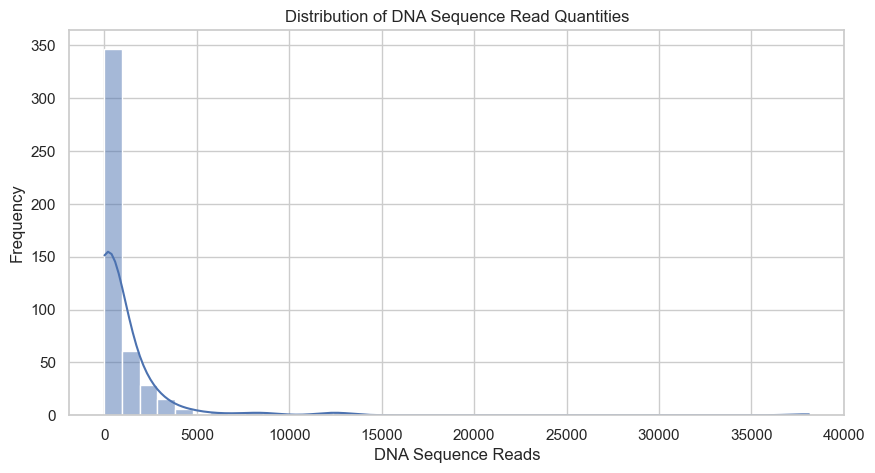

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    spike["organismQuantity"],
    bins=40,
    kde=True
)

plt.title("Distribution of DNA Sequence Read Quantities")
plt.xlabel("DNA Sequence Reads")
plt.ylabel("Frequency")

plt.show()

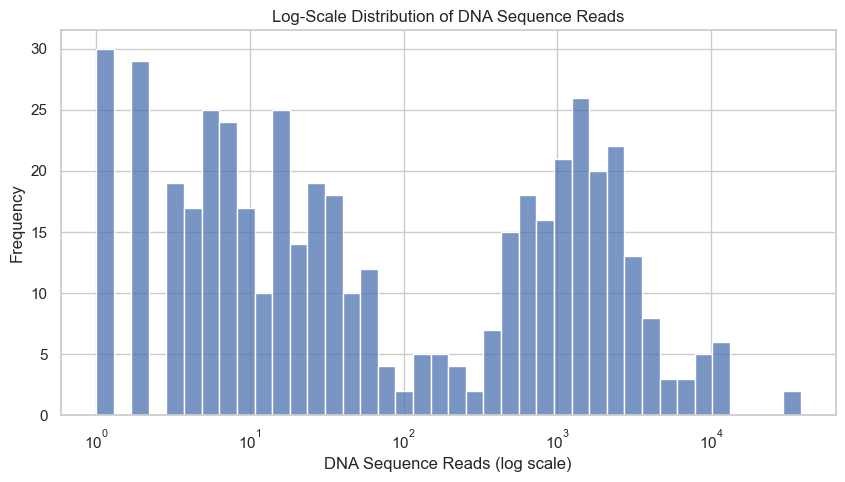

In [54]:
plt.figure(figsize=(10, 5))

sns.histplot(
    spike["organismQuantity"],
    bins=40,
    log_scale=(True, False)
)

plt.title("Log-Scale Distribution of DNA Sequence Reads")
plt.xlabel("DNA Sequence Reads (log scale)")
plt.ylabel("Frequency")

plt.show()

In [55]:
# Investigate repeated coordinates

coordinate_analysis = (
    spike.groupby(
        ["decimalLatitude", "decimalLongitude"]
    )
    .agg(
        records=("occurrenceID", "count"),
        unique_ids=("occurrenceID", "nunique"),
        total_reads=("organismQuantity", "sum"),
        mean_reads=("organismQuantity", "mean"),
        max_reads=("organismQuantity", "max")
    )
    .sort_values("records", ascending=False)
)

print("Coordinate-level analysis:")
print(coordinate_analysis.to_string())

print("\nRepeated coordinate-date combinations:")

print(
    spike.groupby(
        ["eventDate", "decimalLatitude", "decimalLongitude"]
    )
    .agg(
        records=("occurrenceID", "count"),
        total_reads=("organismQuantity", "sum"),
        mean_reads=("organismQuantity", "mean")
    )
    .query("records > 1")
    .sort_values("records", ascending=False)
    .to_string()
)

Coordinate-level analysis:
                                  records  unique_ids  total_reads   mean_reads  max_reads
decimalLatitude decimalLongitude                                                          
21.827841       89.195423              65          65     118689.0  1825.984615    38118.0
21.756580       89.223058              38          38      56511.0  1487.131579    12408.0
21.703931       89.261001              36          36      20401.0   566.694444     2327.0
21.756580       89.223017              36          36      12603.0   350.083333     2226.0
21.703917       89.260995              35          35      21459.0   613.114286     3498.0
21.703521       89.261482              29          29      32851.0  1132.793103     8390.0
21.754752       89.283835              29          29      23590.0   813.448276     4566.0
21.754890       89.284180              28          28      38925.0  1390.178571    12377.0
21.754946       89.283766              28          28      3537

In [56]:
print("Duplicate occurrence IDs:")

print(
    spike["occurrenceID"].duplicated().sum()
)

print("\nDuplicate complete rows:")

print(
    spike.duplicated().sum()
)

Duplicate occurrence IDs:
0

Duplicate complete rows:
0


In [57]:
# Extract apparent sample identifiers

spike["sample_id"] = spike["occurrenceID"].str.extract(
    r"_(EE\d+)_12s_"
)

spike["asv_id"] = spike["occurrenceID"].str.extract(
    r"(asv\.\d+)"
)

spike["assay"] = spike["occurrenceID"].str.extract(
    r"_12s_(.+)$"
)

print("Unique sample IDs:")
print(spike["sample_id"].nunique())

print("\nRecords per sample:")
print(
    spike["sample_id"].value_counts().to_string()
)

print("\nUnique ASV identifiers:")
print(spike["asv_id"].nunique())

print("\nAssay distribution:")
print(spike["assay"].value_counts())

Unique sample IDs:
19

Records per sample:
sample_id
EE0336    35
EE0350    35
EE0362    35
EE0348    33
EE0330    27
EE0337    27
EE0345    26
EE0365    25
EE0351    25
EE0338    25
EE0334    23
EE0360    23
EE0331    21
EE0347    19
EE0332    15
EE0361    15
EE0339    15
EE0363     7
EE0364     7

Unique ASV identifiers:
64

Assay distribution:
assay
teleo       194
mifish      126
mimammal    118
Name: count, dtype: int64


In [58]:
# Sampling unit distribution by date

sample_analysis = (
    spike.groupby(["eventDate", "sample_id"])
    .agg(
        records=("occurrenceID", "count"),
        unique_asvs=("asv_id", "nunique"),
        total_reads=("organismQuantity", "sum"),
        latitude=("decimalLatitude", "first"),
        longitude=("decimalLongitude", "first")
    )
    .reset_index()
)

print(sample_analysis.to_string(index=False))

                eventDate sample_id  records  unique_asvs  total_reads  latitude  longitude
2023-01-08 00:00:00+00:00    EE0339       15           14       2356.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0345       26           25       9997.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0347       19           18     100602.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0348       33           31      10986.0 21.756580  89.223017
2023-01-08 00:00:00+00:00    EE0362       35           33      52884.0 21.756580  89.223058
2023-01-08 00:00:00+00:00    EE0363        7            6        167.0 21.756641  89.223120
2023-01-08 00:00:00+00:00    EE0364        7            7       3042.0 21.828443  89.195000
2023-01-09 00:00:00+00:00    EE0330       27           26      31537.0 21.703521  89.261482
2023-01-09 00:00:00+00:00    EE0331       21           19       6691.0 21.754740  89.283996
2023-01-09 00:00:00+00:00    EE0332       15           14      23917.0 21.793210

In [59]:
# Extract sample IDs from occurrenceID

spike["sample_id"] = spike["occurrenceID"].str.extract(
    r"_(EE\d+)_"
)

print("Total records:", len(spike))

print("Matched sample IDs:",
      spike["sample_id"].notna().sum())

print("Unmatched sample IDs:",
      spike["sample_id"].isna().sum())

print("\nUnmatched occurrence IDs:")

print(
    spike.loc[
        spike["sample_id"].isna(),
        "occurrenceID"
    ].to_string(index=False)
)

print("\nSample distribution:")

print(
    spike["sample_id"]
    .value_counts(dropna=False)
    .sort_index()
)

Total records: 476
Matched sample IDs: 476
Unmatched sample IDs: 0

Unmatched occurrence IDs:
Series([], )

Sample distribution:
sample_id
EE0330    29
EE0331    22
EE0332    17
EE0334    26
EE0336    36
EE0337    29
EE0338    28
EE0339    16
EE0345    28
EE0347    21
EE0348    36
EE0350    35
EE0351    28
EE0360    26
EE0361    17
EE0362    38
EE0363     7
EE0364     9
EE0365    28
Name: count, dtype: int64


In [60]:
# Compare sample-level record counts

check_1 = spike.groupby("sample_id").size().sort_index()

check_2 = (
    sample_analysis.groupby("sample_id")["records"]
    .sum()
    .sort_index()
)

comparison = pd.DataFrame({
    "direct_count": check_1,
    "date_grouped_count": check_2
}).fillna(0)

comparison["difference"] = (
    comparison["direct_count"]
    - comparison["date_grouped_count"]
)

print(comparison.to_string())

print("\nTotal direct records:", check_1.sum())
print("Total date-grouped records:", check_2.sum())
print("Total difference:", comparison["difference"].sum())

           direct_count  date_grouped_count  difference
sample_id                                              
EE0330               29                  27           2
EE0331               22                  21           1
EE0332               17                  15           2
EE0334               26                  23           3
EE0336               36                  35           1
EE0337               29                  27           2
EE0338               28                  25           3
EE0339               16                  15           1
EE0345               28                  26           2
EE0347               21                  19           2
EE0348               36                  33           3
EE0350               35                  35           0
EE0351               28                  25           3
EE0360               26                  23           3
EE0361               17                  15           2
EE0362               38                  35     

In [61]:
print("Missing eventDate:",
      spike["eventDate"].isna().sum())

print("Missing sample_id:",
      spike["sample_id"].isna().sum())

print("Missing occurrenceID:",
      spike["occurrenceID"].isna().sum())

print("\nRecords with missing eventDate:")

print(
    spike.loc[
        spike["eventDate"].isna(),
        ["occurrenceID", "sample_id", "eventDate"]
    ].to_string(index=False)
)

Missing eventDate: 0
Missing sample_id: 0
Missing occurrenceID: 0

Records with missing eventDate:
Empty DataFrame
Columns: [occurrenceID, sample_id, eventDate]
Index: []


In [62]:
sample_analysis = (
    spike.groupby(
        ["eventDate", "sample_id"],
        dropna=False
    )
    .agg(
        records=("occurrenceID", "count"),
        unique_asvs=("occurrenceID", "nunique"),
        total_reads=("organismQuantity", "sum"),
        latitude=("decimalLatitude", "first"),
        longitude=("decimalLongitude", "first")
    )
    .reset_index()
)

print(sample_analysis.to_string(index=False))

print("\nTotal grouped records:",
      sample_analysis["records"].sum())

                eventDate sample_id  records  unique_asvs  total_reads  latitude  longitude
2023-01-08 00:00:00+00:00    EE0339       16           16       3032.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0345       28           28      12250.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0347       21           21     103407.0 21.827841  89.195423
2023-01-08 00:00:00+00:00    EE0348       36           36      12603.0 21.756580  89.223017
2023-01-08 00:00:00+00:00    EE0362       38           38      56511.0 21.756580  89.223058
2023-01-08 00:00:00+00:00    EE0363        7            7        167.0 21.756641  89.223120
2023-01-08 00:00:00+00:00    EE0364        9            9       3785.0 21.828443  89.195000
2023-01-09 00:00:00+00:00    EE0330       29           29      32851.0 21.703521  89.261482
2023-01-09 00:00:00+00:00    EE0331       22           22       6856.0 21.754740  89.283996
2023-01-09 00:00:00+00:00    EE0332       17           17      27181.0 21.793210

In [63]:
# Spatial sampling effort

spatial_effort = (
    spike.groupby(
        ["decimalLatitude", "decimalLongitude"]
    )
    .agg(
        records=("occurrenceID", "count"),
        samples=("sample_id", "nunique"),
        total_reads=("organismQuantity", "sum"),
        unique_asvs=("occurrenceID", "nunique")
    )
    .reset_index()
    .sort_values("records", ascending=False)
)

print("Spatial sampling effort:")
print(spatial_effort.to_string(index=False))

print("\nSummary statistics:")

print(
    spatial_effort[
        ["records", "samples", "total_reads"]
    ].describe()
)

Spatial sampling effort:
 decimalLatitude  decimalLongitude  records  samples  total_reads  unique_asvs
       21.827841         89.195423       65        3     118689.0           65
       21.756580         89.223058       38        1      56511.0           38
       21.703931         89.261001       36        1      20401.0           36
       21.756580         89.223017       36        1      12603.0           36
       21.703917         89.260995       35        1      21459.0           35
       21.703521         89.261482       29        1      32851.0           29
       21.754752         89.283835       29        1      23590.0           29
       21.754890         89.284180       28        1      38925.0           28
       21.754946         89.283766       28        1      35378.0           28
       21.793305         89.280875       28        1      30406.0           28
       21.703926         89.261013       26        1      18902.0           26
       21.793313         89

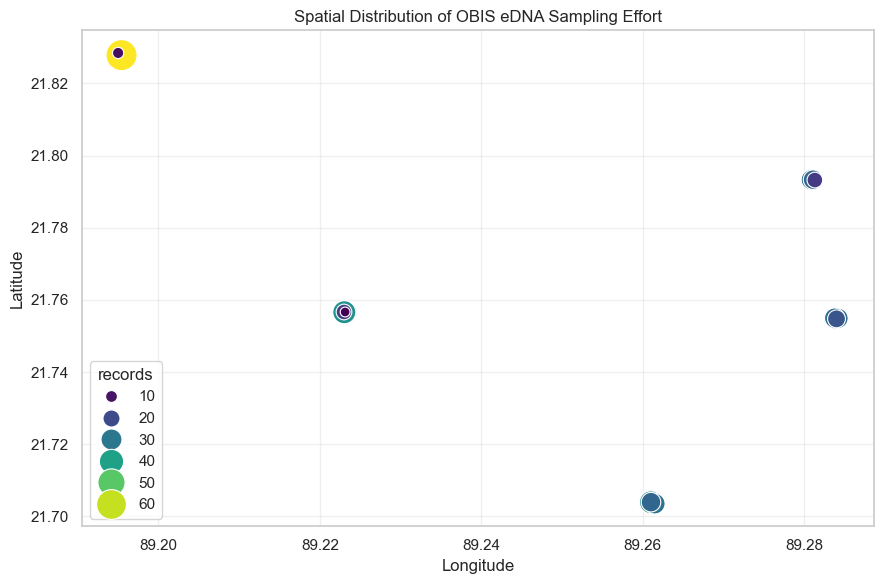

In [64]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=spatial_effort,
    x="decimalLongitude",
    y="decimalLatitude",
    size="records",
    hue="records",
    sizes=(50, 500),
    palette="viridis",
    legend="brief"
)

plt.title("Spatial Distribution of OBIS eDNA Sampling Effort")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# Verify the aggregation without losing records

print("Original records:", len(spike))

sample_check = (
    spike.groupby(["eventDate", "sample_id"])
    .size()
    .reset_index(name="records")
)

print("Grouped records:", sample_check["records"].sum())

print("Difference:",
      len(spike) - sample_check["records"].sum())

print("Number of sample-date groups:", len(sample_check))

Original records: 476
Grouped records: 476
Difference: 0
Number of sample-date groups: 19


In [66]:
# Species-level summary

species_summary = (
    spike.groupby("scientificName")
    .agg(
        observations=("occurrenceID", "count"),
        total_reads=("organismQuantity", "sum"),
        mean_reads=("organismQuantity", "mean"),
        unique_samples=("sample_id", "nunique")
    )
    .sort_values("observations", ascending=False)
)

print(species_summary)

                      observations  total_reads   mean_reads  unique_samples
scientificName                                                              
Setipinna tenuifilis           476     494572.0  1039.016807              19


In [67]:
# Temporal distribution of eDNA observations

temporal_summary = (
    spike.groupby("eventDate")
    .agg(
        observations=("occurrenceID", "count"),
        unique_samples=("sample_id", "nunique"),
        total_reads=("organismQuantity", "sum"),
        mean_reads=("organismQuantity", "mean")
    )
    .reset_index()
)

print(temporal_summary.to_string(index=False))

                eventDate  observations  unique_samples  total_reads  mean_reads
2023-01-08 00:00:00+00:00           155               7     191755.0 1237.129032
2023-01-09 00:00:00+00:00           321              12     302817.0  943.355140


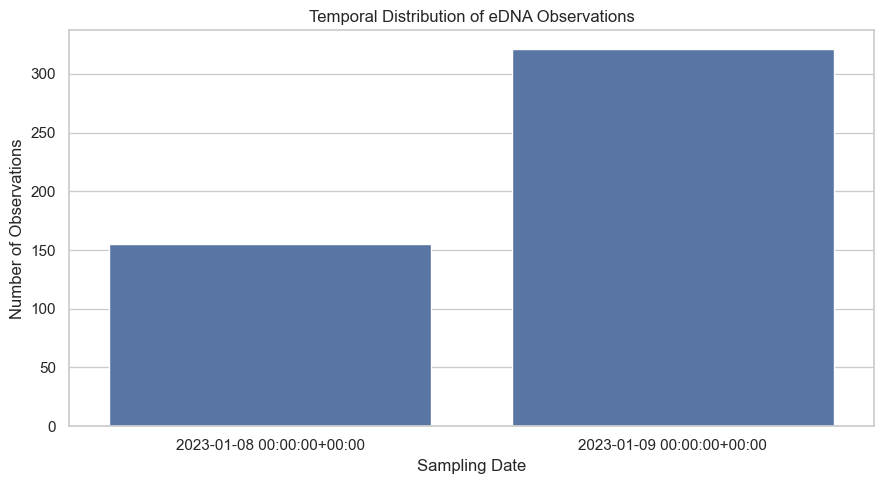

In [68]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=temporal_summary,
    x="eventDate",
    y="observations"
)

plt.title("Temporal Distribution of eDNA Observations")
plt.xlabel("Sampling Date")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [69]:
# Normalize observations and DNA reads by sampling effort

temporal_summary["observations_per_sample"] = (
    temporal_summary["observations"] /
    temporal_summary["unique_samples"]
)

temporal_summary["reads_per_sample"] = (
    temporal_summary["total_reads"] /
    temporal_summary["unique_samples"]
)

print(
    temporal_summary[
        [
            "eventDate",
            "observations_per_sample",
            "reads_per_sample"
        ]
    ].to_string(index=False)
)

                eventDate  observations_per_sample  reads_per_sample
2023-01-08 00:00:00+00:00                22.142857      27393.571429
2023-01-09 00:00:00+00:00                26.750000      25234.750000


In [71]:
# Sample-level variability analysis

sample_variability = (
    spike.groupby(["eventDate", "sample_id"])
    .agg(
        observations=("occurrenceID", "count"),
        total_reads=("organismQuantity", "sum")
    )
    .reset_index()
)

print("Sample-level statistics:")

print(
    sample_variability.groupby("eventDate")[
        ["observations", "total_reads"]
    ].agg(["mean", "std", "min", "max"]).round(2)
)

Sample-level statistics:
                          observations                total_reads            \
                                  mean    std min max        mean       std   
eventDate                                                                     
2023-01-08 00:00:00+00:00        22.14  12.38   7  38    27393.57  38656.81   
2023-01-09 00:00:00+00:00        26.75   5.89  17  36    25234.75   9217.08   

                                             
                              min       max  
eventDate                                    
2023-01-08 00:00:00+00:00   167.0  103407.0  
2023-01-09 00:00:00+00:00  6856.0   38925.0  


In [72]:
# Rank samples by total DNA sequence reads

print(
    sample_variability
    .sort_values("total_reads", ascending=False)
    .to_string(index=False)
)

                eventDate sample_id  observations  total_reads
2023-01-08 00:00:00+00:00    EE0347            21     103407.0
2023-01-08 00:00:00+00:00    EE0362            38      56511.0
2023-01-09 00:00:00+00:00    EE0365            28      38925.0
2023-01-09 00:00:00+00:00    EE0338            28      35378.0
2023-01-09 00:00:00+00:00    EE0330            29      32851.0
2023-01-09 00:00:00+00:00    EE0361            17      31526.0
2023-01-09 00:00:00+00:00    EE0351            28      30406.0
2023-01-09 00:00:00+00:00    EE0332            17      27181.0
2023-01-09 00:00:00+00:00    EE0337            29      23590.0
2023-01-09 00:00:00+00:00    EE0350            35      21459.0
2023-01-09 00:00:00+00:00    EE0336            36      20401.0
2023-01-09 00:00:00+00:00    EE0334            26      18902.0
2023-01-09 00:00:00+00:00    EE0360            26      15342.0
2023-01-08 00:00:00+00:00    EE0348            36      12603.0
2023-01-08 00:00:00+00:00    EE0345            28      

In [73]:
# Coefficient of variation (CV)

cv_summary = (
    sample_variability
    .groupby("eventDate")
    ["total_reads"]
    .agg(["mean", "std"])
)

cv_summary["CV (%)"] = (
    cv_summary["std"] /
    cv_summary["mean"]
) * 100

print(cv_summary.round(2))

                               mean       std  CV (%)
eventDate                                            
2023-01-08 00:00:00+00:00  27393.57  38656.81  141.12
2023-01-09 00:00:00+00:00  25234.75   9217.08   36.53


In [74]:
# Identify taxonomic-related columns

taxonomic_keywords = [
    "scientific",
    "taxon",
    "species",
    "genus",
    "family",
    "order",
    "class",
    "kingdom",
    "identification"
]

taxonomic_columns = [
    col for col in spike.columns
    if any(keyword in col.lower() for keyword in taxonomic_keywords)
]

print("Taxonomic columns:")
print(taxonomic_columns)

Taxonomic columns:
['class', 'classid', 'family', 'familyid', 'genus', 'genusid', 'identificationID', 'infraclass', 'infraclassid', 'kingdom', 'kingdomid', 'order', 'orderid', 'scientificName', 'scientificNameID', 'species', 'speciesid', 'subclass', 'subclassid', 'superorder', 'superorderid', 'taxonID', 'taxonRank', 'originalScientificName', 'identificationVerificationStatus', 'identificationRemarks', 'scientificNameAuthorship', 'gigaclass', 'gigaclassid', 'superclass', 'superclassid', 'verbatimIdentification']


In [75]:
for col in taxonomic_columns:

    print(f"\n--- {col} ---")

    print("Unique values:", spike[col].nunique())

    print("Missing values:", spike[col].isna().sum())

    print(spike[col].value_counts(dropna=False).head(15))


--- class ---
Unique values: 1
Missing values: 0
class
Teleostei    476
Name: count, dtype: int64

--- classid ---
Unique values: 1
Missing values: 0
classid
293496    476
Name: count, dtype: int64

--- family ---
Unique values: 1
Missing values: 0
family
Engraulidae    476
Name: count, dtype: int64

--- familyid ---
Unique values: 1
Missing values: 0
familyid
125465    476
Name: count, dtype: int64

--- genus ---
Unique values: 1
Missing values: 0
genus
Setipinna    476
Name: count, dtype: int64

--- genusid ---
Unique values: 1
Missing values: 0
genusid
270883    476
Name: count, dtype: int64

--- identificationID ---
Unique values: 0
Missing values: 476
identificationID
NaN    476
Name: count, dtype: int64

--- infraclass ---
Unique values: 0
Missing values: 476
infraclass
NaN    476
Name: count, dtype: int64

--- infraclassid ---
Unique values: 0
Missing values: 476
infraclassid
NaN    476
Name: count, dtype: int64

--- kingdom ---
Unique values: 1
Missing values: 0
kingdom
Animal

In [76]:
species_check = (
    spike.groupby("scientificName")
    .agg(
        observations=("occurrenceID", "count"),
        unique_samples=("sample_id", "nunique"),
        unique_taxa=("scientificName", "nunique")
    )
)

print(species_check)

                      observations  unique_samples  unique_taxa
scientificName                                                 
Setipinna tenuifilis           476              19            1


In [77]:
# Inspect complete taxonomic hierarchy

taxonomic_fields = [
    "scientificName",
    "verbatimIdentification",
    "taxonRank",
    "taxonID",
    "acceptedNameUsage",
    "kingdom",
    "phylum",
    "class",
    "order",
    "family",
    "genus"
]

available_fields = [
    col for col in taxonomic_fields
    if col in spike.columns
]

print("Available fields:")
print(available_fields)

print("\nUnique taxonomic combinations:")

print(
    spike[available_fields]
    .drop_duplicates()
    .to_string(index=False)
)

Available fields:
['scientificName', 'verbatimIdentification', 'taxonRank', 'taxonID', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus']

Unique taxonomic combinations:
      scientificName verbatimIdentification taxonRank  taxonID  kingdom   phylum     class        order      family     genus
Setipinna tenuifilis   Setipinna tenuifilis   species      NaN Animalia Chordata Teleostei Clupeiformes Engraulidae Setipinna


In [78]:
# Geographical data quality assessment

print("Missing latitude:",
      spike["decimalLatitude"].isna().sum())

print("Missing longitude:",
      spike["decimalLongitude"].isna().sum())

print("Invalid latitude:",
      (~spike["decimalLatitude"].between(-90, 90)).sum())

print("Invalid longitude:",
      (~spike["decimalLongitude"].between(-180, 180)).sum())

# Bay of Bengal boundaries
min_lon, max_lon = 78, 100
min_lat, max_lat = 0, 23

inside_region = (
    spike["decimalLatitude"].between(min_lat, max_lat) &
    spike["decimalLongitude"].between(min_lon, max_lon)
)

print("\nRecords inside Bay of Bengal:",
      inside_region.sum())

print("Records outside Bay of Bengal:",
      (~inside_region).sum())

Missing latitude: 0
Missing longitude: 0
Invalid latitude: 0
Invalid longitude: 0

Records inside Bay of Bengal: 476
Records outside Bay of Bengal: 0


In [79]:
# Inspect records outside the study region

outside_region = spike.loc[
    ~inside_region,
    [
        "scientificName",
        "eventDate",
        "decimalLatitude",
        "decimalLongitude"
    ]
]

print(outside_region.to_string(index=False))

Empty DataFrame
Columns: [scientificName, eventDate, decimalLatitude, decimalLongitude]
Index: []


In [80]:
# Inspect dataset provenance and sampling metadata

metadata_columns = [
    "datasetID",
    "datasetName",
    "eventID",
    "sample_id",
    "samplingProtocol",
    "institutionCode",
    "collectionCode",
    "basisOfRecord",
    "coordinateUncertaintyInMeters"
]

available_columns = [
    col for col in metadata_columns
    if col in spike.columns
]

for col in available_columns:

    print(f"\n--- {col} ---")

    print(
        spike[col]
        .value_counts(dropna=False)
        .head(15)
    )


--- datasetName ---
datasetName
NaN    476
Name: count, dtype: int64

--- eventID ---
eventID
NaN    476
Name: count, dtype: int64

--- sample_id ---
sample_id
EE0362    38
EE0348    36
EE0336    36
EE0350    35
EE0330    29
EE0337    29
EE0345    28
EE0338    28
EE0365    28
EE0351    28
EE0334    26
EE0360    26
EE0331    22
EE0347    21
EE0332    17
Name: count, dtype: int64

--- samplingProtocol ---
samplingProtocol
eDNA expeditions citizen science sampling    476
Name: count, dtype: int64

--- institutionCode ---
institutionCode
NaN    476
Name: count, dtype: int64

--- collectionCode ---
collectionCode
NaN    476
Name: count, dtype: int64

--- basisOfRecord ---
basisOfRecord
MachineObservation    476
Name: count, dtype: int64

--- coordinateUncertaintyInMeters ---
coordinateUncertaintyInMeters
NaN    476
Name: count, dtype: int64


In [81]:
# Spatial coverage statistics

print("Latitude range:")
print(spike["decimalLatitude"].agg(["min", "max"]))

print("\nLongitude range:")
print(spike["decimalLongitude"].agg(["min", "max"]))

print("\nUnique sampling locations:")

print(
    spike.groupby(
        ["decimalLatitude", "decimalLongitude"]
    ).size().sort_values(ascending=False)
)

Latitude range:
min    21.703521
max    21.828443
Name: decimalLatitude, dtype: float64

Longitude range:
min    89.19500
max    89.28418
Name: decimalLongitude, dtype: float64

Unique sampling locations:
decimalLatitude  decimalLongitude
21.827841        89.195423           65
21.756580        89.223058           38
21.703931        89.261001           36
21.756580        89.223017           36
21.703917        89.260995           35
21.703521        89.261482           29
21.754752        89.283835           29
21.754890        89.284180           28
21.754946        89.283766           28
21.793305        89.280875           28
21.703926        89.261013           26
21.793313        89.281088           26
21.754740        89.283996           22
21.756639        89.222982           17
21.793210        89.281313           17
21.828443        89.195000            9
21.756641        89.223120            7
dtype: int64


## OBIS EDA: Data Limitations

1. The inspected subset contains only one identified species.
2. Sampling observations are concentrated in a limited
   geographical area.
3. Sampling dates cover only January 8 and 9, 2023.
4. Sampling effort varies between sample IDs.
5. The dataset should not be interpreted as representative
   of overall Bay of Bengal biodiversity.
6. Additional OBIS records are required for broader
   biodiversity analysis.

In [82]:
# Identify all potentially useful metadata columns

keywords = [
    "dataset",
    "event",
    "institution",
    "collection",
    "protocol",
    "locality",
    "location",
    "sampling",
    "recordedby",
    "identifiedby",
    "publisher",
    "license",
    "references",
    "citation",
    "catalog",
    "occurrence"
]

metadata_columns = [
    col for col in spike.columns
    if any(word in col.lower() for word in keywords)
]

print("Metadata columns found:")
print(metadata_columns)

print("\nMetadata completeness:")

metadata_report = pd.DataFrame({
    "column": metadata_columns,
    "non_missing": [
        spike[col].notna().sum()
        for col in metadata_columns
    ],
    "unique_values": [
        spike[col].nunique()
        for col in metadata_columns
    ]
})

print(
    metadata_report.sort_values(
        "non_missing",
        ascending=False
    ).to_string(index=False)
)

Metadata columns found:
['catalogNumber', 'collectionCode', 'datasetName', 'eventDate', 'eventTime', 'identifiedBy', 'institutionCode', 'license', 'occurrenceID', 'occurrenceStatus', 'recordedBy', 'references', 'verbatimEventDate', 'verbatimLocality', 'dataset_id', 'identifiedByID', 'recordedByID', 'occurrenceRemarks', 'eventType', 'locality', 'samplingProtocol', 'eventID', 'eventRemarks', 'locationID', 'eventDate_parsed']

Metadata completeness:
           column  non_missing  unique_values
        eventDate          476              2
     occurrenceID          476            476
         locality          476              6
       locationID          476              5
     eventRemarks          476              2
 eventDate_parsed          476              2
       dataset_id          476              1
       recordedBy          476              1
 occurrenceStatus          476              1
 samplingProtocol          476              1
          license            0             

In [83]:
# Inspect actual metadata values

important_metadata = [
    "dataset_id",
    "locality",
    "locationID",
    "eventRemarks",
    "recordedBy",
    "samplingProtocol",
    "occurrenceStatus",
    "eventDate"
]

for col in important_metadata:

    if col in spike.columns:

        print(f"\n{'='*50}")
        print(f"FIELD: {col}")
        print(f"{'='*50}")

        print(
            spike[col]
            .value_counts(dropna=False)
            .to_string()
        )


FIELD: dataset_id
dataset_id
05fe0873-13d5-485a-a7cc-2f4a90ea6398    476

FIELD: locality
locality
Sundarban west wildlife sanctuary      186
Sundarbans west wildlife sanctuary     154
Sundarbans West Wildlife Sanctuary      63
Sundarbans West Wildlife  Sanctuary     28
Sundarban's west wildlife sanctuary     28
Sundarban West Wildlife Sanctuary       17

FIELD: locationID
locationID
Sundarbans 5    126
Sundarbans 3    107
Sundarbans 4     98
Sundarbans 1     74
Sundarbans 2     71

FIELD: eventRemarks
eventRemarks
sequencing batch 2    303
sequencing batch 1    173

FIELD: recordedBy
recordedBy
Hugo Gante    476

FIELD: samplingProtocol
samplingProtocol
eDNA expeditions citizen science sampling    476

FIELD: occurrenceStatus
occurrenceStatus
present    476

FIELD: eventDate
eventDate
2023-01-09 00:00:00+00:00    321
2023-01-08 00:00:00+00:00    155


In [86]:
%pip install requests

     ---------------------------------------- 0.0/73.1 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/73.1 kB ? eta -:--:--
     ---------------------------------------  71.7/73.1 kB 1.3 MB/s eta 0:00:01
     -------------------------------------- 73.1/73.1 kB 997.4 kB/s eta 0:00:00
     ---------------------------------------- 0.0/215.4 kB ? eta -:--:--
     --------------------------- ---------- 153.6/215.4 kB 3.1 MB/s eta 0:00:01
     -------------------------------------- 215.4/215.4 kB 4.4 MB/s eta 0:00:00
     ---------------------------------------- 0.0/69.6 kB ? eta -:--:--
     ---------------------------------------- 69.6/69.6 kB 4.0 MB/s eta 0:00:00
     ---------------------------------------- 0.0/135.7 kB ? eta -:--:--
     -------------------------------------- 135.7/135.7 kB 4.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
import requests
import json

dataset_id = "05fe0873-13d5-485a-a7cc-2f4a90ea6398"

url = f"https://api.obis.org/v3/dataset/{dataset_id}"

response = requests.get(url, timeout=30)

response.raise_for_status()

dataset_metadata = response.json()

print(
    json.dumps(
        dataset_metadata,
        indent=4
    )
)

{
    "total": 1,
    "results": [
        {
            "id": "05fe0873-13d5-485a-a7cc-2f4a90ea6398",
            "url": "https://ipt.obis.org/secretariat/resource?r=edna-the-sundarbans",
            "archive": "https://ipt.obis.org/secretariat/archive.do?r=edna-the-sundarbans",
            "published": "2026-10-13T11:39:10.000Z",
            "created": "2024-12-08T10:09:34.592Z",
            "updated": "2026-10-13T13:36:09.872Z",
            "core": "occurrence",
            "extensions": [
                "dnaderiveddata"
            ],
            "statistics": {
                "Event": 0,
                "absence": 0,
                "dropped": 26507,
                "Occurrence": 73568,
                "DNADerivedData": 73568,
                "MeasurementOrFact": 0
            },
            "extent": "POLYGON((89.1949998 21.703521,89.28418 21.703521,89.28418 21.8284425,89.1949998 21.8284425,89.1949998 21.703521))",
            "title": "UNESCO eDNA expedition in The Sundarbans 

In [88]:
for col in ["samplingProtocol", "eventRemarks", "recordedBy"]:
    print(f"\n{col}:")
    print(spike[col].dropna().unique())


samplingProtocol:
['eDNA expeditions citizen science sampling']

eventRemarks:
['sequencing batch 1' 'sequencing batch 2']

recordedBy:
['Hugo Gante']


In [89]:
# Inspect the original OBIS dataset metadata

dataset_id = "05fe0873-13d5-485a-a7cc-2f4a90ea6398"

url = f"https://api.obis.org/v3/dataset/{dataset_id}"

response = requests.get(url)
response.raise_for_status()

dataset_info = response.json()

for field in [
    "id",
    "title",
    "url",
    "archive",
    "created",
    "updated",
    "published",
    "citation",
    "extent",
    "statistics"
]:
    print(f"\n{field}:")
    print(dataset_info.get(field))


id:
None

title:
None

url:
None

archive:
None

created:
None

updated:
None

published:
None

citation:
None

extent:
None

statistics:
None


In [90]:
# Sampling methodology summary

sampling_summary = {
    "sampling_protocol": spike["samplingProtocol"].value_counts(
        dropna=False
    ),
    "event_remarks": spike["eventRemarks"].value_counts(
        dropna=False
    ),
    "recorded_by": spike["recordedBy"].value_counts(
        dropna=False
    ),
    "locality": spike["locality"].value_counts(
        dropna=False
    )
}

for name, result in sampling_summary.items():
    print(f"\n{'='*50}")
    print(name.upper())
    print(result)


SAMPLING_PROTOCOL
samplingProtocol
eDNA expeditions citizen science sampling    476
Name: count, dtype: int64

EVENT_REMARKS
eventRemarks
sequencing batch 2    303
sequencing batch 1    173
Name: count, dtype: int64

RECORDED_BY
recordedBy
Hugo Gante    476
Name: count, dtype: int64

LOCALITY
locality
Sundarban west wildlife sanctuary      186
Sundarbans west wildlife sanctuary     154
Sundarbans West Wildlife Sanctuary      63
Sundarbans West Wildlife  Sanctuary     28
Sundarban's west wildlife sanctuary     28
Sundarban West Wildlife Sanctuary       17
Name: count, dtype: int64


In [91]:
# Compare sequencing batches

batch_summary = (
    spike.groupby("eventRemarks")
    .agg(
        observations=("occurrenceID", "count"),
        unique_samples=("sample_id", "nunique"),
        total_reads=("organismQuantity", "sum"),
        mean_reads=("organismQuantity", "mean"),
        median_reads=("organismQuantity", "median"),
        std_reads=("organismQuantity", "std")
    )
)

print(batch_summary.round(2))

                    observations  unique_samples  total_reads  mean_reads  \
eventRemarks                                                                
sequencing batch 1           173               9     237789.0     1374.50   
sequencing batch 2           303              10     256783.0      847.47   

                    median_reads  std_reads  
eventRemarks                                 
sequencing batch 1          51.0    4459.07  
sequencing batch 2          32.0    1811.07  


In [92]:
# Normalize locality text for inspection

spike["locality_normalized"] = (
    spike["locality"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace("'", "", regex=False)
)

print(
    spike.groupby("locality_normalized")
    .size()
    .sort_values(ascending=False)
)

locality_normalized
sundarbans west wildlife sanctuary    273
sundarban west wildlife sanctuary     203
dtype: int64


In [93]:
dataset_metadata = dataset_info["results"][0]

for field in [
    "id",
    "title",
    "url",
    "archive",
    "created",
    "updated",
    "published",
    "citation",
    "statistics",
    "extent"
]:
    print(f"\n{field}:")
    print(dataset_metadata.get(field))


id:
05fe0873-13d5-485a-a7cc-2f4a90ea6398

title:
UNESCO eDNA expedition in The Sundarbans (Bangladesh): February 2023

url:
https://ipt.obis.org/secretariat/resource?r=edna-the-sundarbans

archive:
https://ipt.obis.org/secretariat/archive.do?r=edna-the-sundarbans

created:
2024-12-08T10:09:34.592Z

updated:
2026-10-13T13:36:09.872Z

published:
2026-10-13T11:39:10.000Z

citation:
Ahsan Habib K, Rashed M, Sakib N, Suominen S, Provoost P, Gillard E, Douvere F, Appeltans W (2026). UNESCO eDNA expedition in The Sundarbans (Bangladesh): February 2023. Version 2.1. OBIS Secretariat. Occurrence dataset. https://doi.org/10.25607/rt4e3h

statistics:
{'Event': 0, 'absence': 0, 'dropped': 26507, 'Occurrence': 73568, 'DNADerivedData': 73568, 'MeasurementOrFact': 0}

extent:
POLYGON((89.1949998 21.703521,89.28418 21.703521,89.28418 21.8284425,89.1949998 21.8284425,89.1949998 21.703521))


In [94]:
# Check whether samples belong to a single sequencing batch

batch_sample_check = (
    spike.groupby("sample_id")
    .agg(
        batches=("eventRemarks", "nunique"),
        batch_name=("eventRemarks", "first"),
        observations=("occurrenceID", "count"),
        total_reads=("organismQuantity", "sum")
    )
)

print("Samples assigned to multiple batches:")
print(batch_sample_check[
    batch_sample_check["batches"] > 1
])

print("\nSamples per sequencing batch:")
print(batch_sample_check["batch_name"].value_counts())

print("\nSample-level read statistics:")
print(
    batch_sample_check.groupby("batch_name")["total_reads"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

Samples assigned to multiple batches:
Empty DataFrame
Columns: [batches, batch_name, observations, total_reads]
Index: []

Samples per sequencing batch:
batch_name
sequencing batch 2    10
sequencing batch 1     9
Name: count, dtype: int64

Sample-level read statistics:
                    count     mean   median       std     min       max
batch_name                                                             
sequencing batch 1      9  26421.0  23590.0  31528.49   167.0  103407.0
sequencing batch 2     10  25678.3  20930.0  14780.69  6856.0   56511.0


In [95]:
# Preserve original locality values

spike["locality_clean"] = (
    spike["locality_normalized"]
    .replace({
        "sundarban west wildlife sanctuary":
        "sundarbans west wildlife sanctuary"
    })
)

print(spike["locality_clean"].value_counts())

print("\nNumber of standardized localities:")
print(spike["locality_clean"].nunique())

locality_clean
sundarbans west wildlife sanctuary    476
Name: count, dtype: int64

Number of standardized localities:
1


In [97]:
%pip install plotly

     ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/9.7 MB 682.7 kB/s eta 0:00:15
     ---------------------------------------- 0.1/9.7 MB 660.6 kB/s eta 0:00:15
      --------------------------------------- 0.1/9.7 MB 1.2 MB/s eta 0:00:08
      --------------------------------------- 0.1/9.7 MB 1.2 MB/s eta 0:00:08
      --------------------------------------- 0.2/9.7 MB 1.4 MB/s eta 0:00:07
     -- ------------------------------------- 0.5/9.7 MB 2.1 MB/s eta 0:00:05
     --- ------------------------------------ 0.7/9.7 MB 2.6 MB/s eta 0:00:04
     ---- ----------------------------------- 1.0/9.7 MB 3.1 MB/s eta 0:00:03
     ------ --------------------------------- 1.5/9.7 MB 4.2 MB/s eta 0:00:02
     ------- -------------------------------- 1.8/9.7 MB 4.7 MB/s eta 0:00:02
     --------- ------------------------------ 2.4/9.7 MB 5.4 MB/s eta 0:00:02
     ----------- ---------------------------- 2.8/9.7 MB 5.8 MB/s e

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
%pip install --upgrade nbformat

     ---------------------------------------- 0.0/79.8 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/79.8 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/79.8 kB ? eta -:--:--
     ------------------- ------------------ 41.0/79.8 kB 393.8 kB/s eta 0:00:01
     -------------------------------------- 79.8/79.8 kB 556.9 kB/s eta 0:00:00
     ---------------------------------------- 0.0/90.6 kB ? eta -:--:--
     --------------------------- ------------ 61.4/90.6 kB ? eta -:--:--
     ---------------------------------------- 90.6/90.6 kB 1.0 MB/s eta 0:00:00
     ---------------------------------------- 0.0/67.5 kB ? eta -:--:--
     ---------------------------------------- 67.5/67.5 kB ? eta 0:00:00
     ---------------------------------------- 0.0/235.8 kB ? eta -:--:--
     ---------------------------- --------- 174.1/235.8 kB 5.3 MB/s eta 0:00:01
     -------------------------------------- 235.8/235.8 kB 3.6 MB/s eta 0:00:00
Note: you may need 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [102]:
import plotly.express as px
import pandas as pd

# Prepare spatial data
map_data = spike.copy()

map_data["decimalLatitude"] = pd.to_numeric(
    map_data["decimalLatitude"], errors="coerce"
)

map_data["decimalLongitude"] = pd.to_numeric(
    map_data["decimalLongitude"], errors="coerce"
)

map_data = map_data.dropna(
    subset=["decimalLatitude", "decimalLongitude", "scientificName"]
)

# Interactive species distribution map
fig = px.scatter_map(
    map_data,
    lat="decimalLatitude",
    lon="decimalLongitude",
    color="scientificName",
    hover_name="scientificName",
    hover_data={
        "decimalLatitude": ":.4f",
        "decimalLongitude": ":.4f",
        "eventDate": True,
        "sample_id": True
    },
    zoom=5,
    height=650,
    title="OBIS Marine Species Spatial Distribution"
)

fig.update_layout(
    map_style="open-street-map",
    legend_title="Species",
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [103]:
spatial_range = (
    map_data.groupby("scientificName")
    .agg(
        observations=("occurrenceID", "count"),
        min_latitude=("decimalLatitude", "min"),
        max_latitude=("decimalLatitude", "max"),
        min_longitude=("decimalLongitude", "min"),
        max_longitude=("decimalLongitude", "max")
    )
    .round(4)
    .reset_index()
)

print("Species-wise geographical distribution:")
print(spatial_range.to_string(index=False))

Species-wise geographical distribution:
      scientificName  observations  min_latitude  max_latitude  min_longitude  max_longitude
Setipinna tenuifilis           476       21.7035       21.8284         89.195        89.2842


In [104]:
region_species = (
    map_data.groupby(["region", "scientificName"])
    .size()
    .reset_index(name="observations")
)

print(region_species.to_string(index=False))

       region       scientificName  observations
Bay of Bengal Setipinna tenuifilis           476
